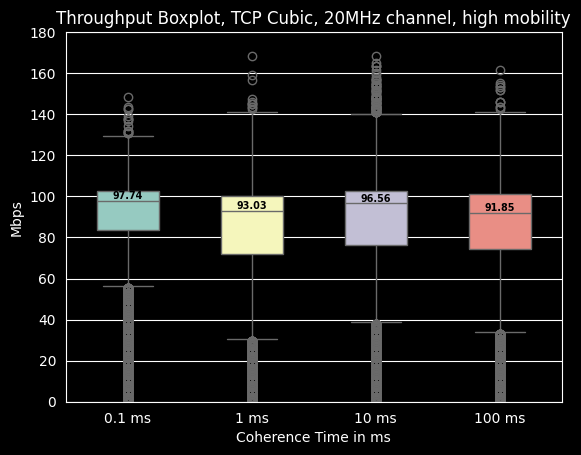

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sys
import os
import seaborn as sns
import csv

# TODO: High mobility
# TODO: DONE Median neben Plot
# TODO: Munich outdoor
# TODO: 80Mhz Kanal
# TODO: IQR (Inter quantil distanzen) Was genau meinte ich damit? 0.25, 0.75, 0.05, 0.95 und outlier
# TODO: DONE Jupyter
# TODO: DONE Zeit messen
# TODO: DONE Zeit plotten, durchschnitt im throughput?
# TODO: DONE Kein Raytracer, kein walk: Kein Crash ohne raytracer, crash mit walk
# TODO: DONE Watchdog script
# TODO: DONE Watchdog script doesn't exit everything cleanly, improvements needed
# TODO 2: DONE Create script to kill all experiments, kill at the end of watchdog.
# TODO: DONE-ish Relative paths
# TODO: DONE Steapcounter (channel calculations) in server

# TODO: Make this path relative!!!
# Set the path to the folder with the throughput results
basepath = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/tp_res_7/"

# Read Throughput from CSV files and return a list
def readThroughput(pathname):
    throughputs = {}
    times = [1, 10, 100, 1000]

    # Go trough all the coherence times
    for i in times:
        throughputs[i] = []

        # Go through the number of experiments
        for j in range (100):
            fname = f"{basepath}throughput_results_{i}_{j+1}.csv"
            try:
                with open(fname, newline='') as csvfile:
                    spamreader = csv.reader(csvfile, delimiter=' ', quotechar='|')
                    # Skip the header line, Strings make for terrible numbers
                    header = next(spamreader, None)

                    # Put the data from the csv into the dictionary at the coherence time
                    for row in spamreader:
                        t_var = ', '.join(row).split(",")[1]
                        throughputs[i].append(float(t_var))
            except FileNotFoundError:
                # print("File ", fname, " not found")
                continue
    # Return all the throughput values at one
    return [throughputs[1], throughputs[10], throughputs[100],throughputs[1000]]

throughput = readThroughput(basepath)

box_plot = sns.boxplot(data=throughput, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(t) for t in throughput]

vertical_offset = [m * 0.01 for m in medians]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + vertical_offset[xtick],
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='black',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Mbps")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 180)

plt.title("Throughput Boxplot, TCP Cubic, 20MHz channel, high mobility")

plt.savefig("throughput_boxplot.png")

# TODO: Why some very high throughput sometimes?


['.idea', 'LICENSE', 'common', 'models', 'ns3sionna_utils.py', 'run_fast.sh', 'run_python_proto.sh', 'tests', '__pycache__', '.DS_Store', 'README.md', 'mobility.py', 'ns3sionna_server.py', 'requirements.txt', 'requirements_cpuonly.txt', 'run_unit_tests.sh', 'run.sh', 'run_incomp.sh', 'stepcounter.txt', 'server.log']


Text(0.5, 1.0, 'Computation time to fixed coherence time')

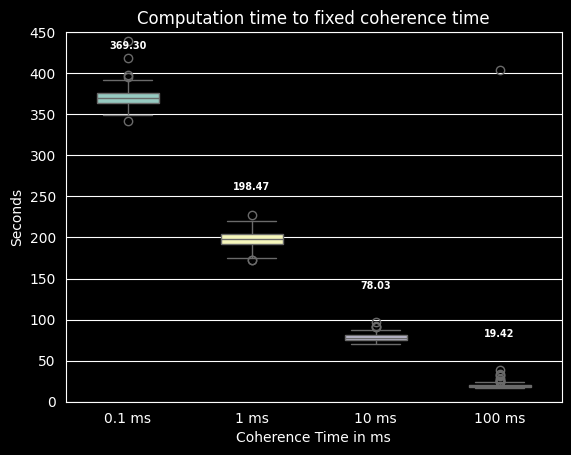

In [2]:
# Plot the time
timepath = '/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/computationtimeHighMobility.csv'
print(os.listdir('../model/ns3sionna'))

def readTime(fname):
    comp_times = {}
    times = [1, 10, 100, 1000]
    # Setup dict
    for i in times:
        comp_times[i] = []
    try:
        with open(fname, newline='') as csvfile:
            spamreader = csv.reader(csvfile, delimiter=',', quotechar='|')
            # Put the data from the csv into the dictionary at the coherence time
            for line in spamreader:
                # Line value is a string, turn into int to use as index
                comp_times[int(line[0])].append(float(line[1]))
    except FileNotFoundError:
        print(f"Could not {timepath} file.")

    return comp_times

timeValue = readTime(timepath)

# print(timeValue)

box_plot = sns.boxplot(data=timeValue, widths=0.5)

# Write medians onto the plot (slightly above the median line)
medians = [np.median(timeValue[t]) for t in timeValue]

for xtick in box_plot.get_xticks():
    box_plot.text(
        xtick,
        medians[xtick] + 60,
        f'{medians[xtick]:.2f}',
        horizontalalignment='center',
        size='x-small',
        color='white',
        weight='semibold'
    )

plt.xlabel("Coherence Time in ms")
plt.ylabel("Seconds")

plt.xticks(ticks=[0, 1, 2, 3], labels=["0.1 ms", "1 ms", "10 ms", "100 ms"])
plt.ylim(0, 450)

plt.title("Computation time to fixed coherence time")

# plt.savefig("throughput_boxplot.png")
# TODO: Why the outliers? Appartment scenario lab00/tmp/models. Callback from sensing mobile. Example mobility sionna snr plot, copy callback, register it.
# TODO: Increase signal strength in performance for munich setting
# Position and SnR (above 6), 30dB
# Claude debugging + stacktracce find crash.

In [3]:
# ── Sweep configuration ──────────────────────────────────────────────────
# Update these to match the paths / settings used in watchdog.sh
import pandas as pd

# Root folder that contains tc0/, tc1/, tc10/, tc100/ sub-directories
# (set by OUTPUT_BASE in watchdog.sh)
results_base = "/home/ccs-lab/jan.zabel/ns-allinone-3.40/ns-3.40/contrib/sionna/examples/results/"

coherence_times = [1, 10, 100, 1000]   # ms  — must match COHERENCE_TIMES in watchdog.sh
num_seeds       = 10                 # END_SEED value used in watchdog.sh

# AP position in the floor-plan (metres) — update to match your C++ scenario
AP_X, AP_Y = -1.0, 0.5

# TX power used in the simulation (dBm) — must match TX_POWER_DBM in the C++ file
TX_POWER_DBM = 20.0


def snr_file(tc, seed):
    return f"{results_base}tc{tc}/snr_results_{tc}_{seed}.csv"

def pos_file(tc, seed):
    return f"{results_base}tc{tc}/position_results_{tc}_{seed}.csv"

def tp_file(tc, seed):
    return f"{results_base}tc{tc}/throughput_results_{tc}_{seed}.csv"


def load_csv(path):
    """Return DataFrame or None if the file is missing."""
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return None


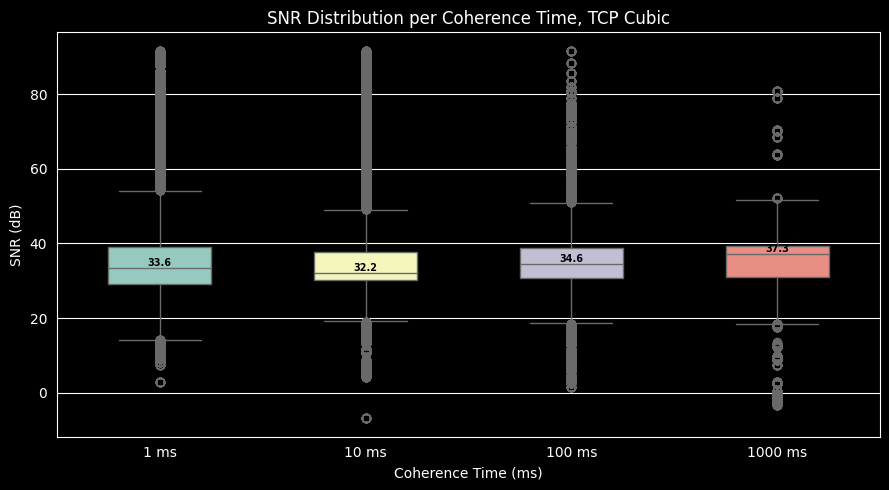

In [4]:
# SNR Plot
snr_by_tc = {tc: [] for tc in coherence_times}

for tc in coherence_times:
    for seed in range(1, num_seeds + 1):
        df = load_csv(snr_file(tc, seed))
        if df is not None:
            snr_by_tc[tc].extend(df['SNR_dB'].tolist())

data_list = [snr_by_tc[tc] for tc in coherence_times]
labels    = [f"{tc} ms" for tc in coherence_times]

fig, ax = plt.subplots(figsize=(9, 5))
bp = sns.boxplot(data=data_list, ax=ax, widths=0.5)

medians  = [np.median(d) if d else float('nan') for d in data_list]
v_off    = [abs(m) * 0.01 for m in medians]
for xtick in bp.get_xticks():
    if not np.isnan(medians[xtick]):
        bp.text(xtick, medians[xtick] + v_off[xtick],
                f'{medians[xtick]:.1f}',
                ha='center', size='x-small', color='black', weight='semibold')

ax.set_xticks(range(len(coherence_times)))
ax.set_xticklabels(labels)
ax.set_xlabel('Coherence Time (ms)')
ax.set_ylabel('SNR (dB)')
ax.set_title('SNR Distribution per Coherence Time, TCP Cubic')
plt.tight_layout()
plt.savefig('snr_boxplot.png', dpi=300, bbox_inches='tight', pad_inches=0.2)
plt.show()


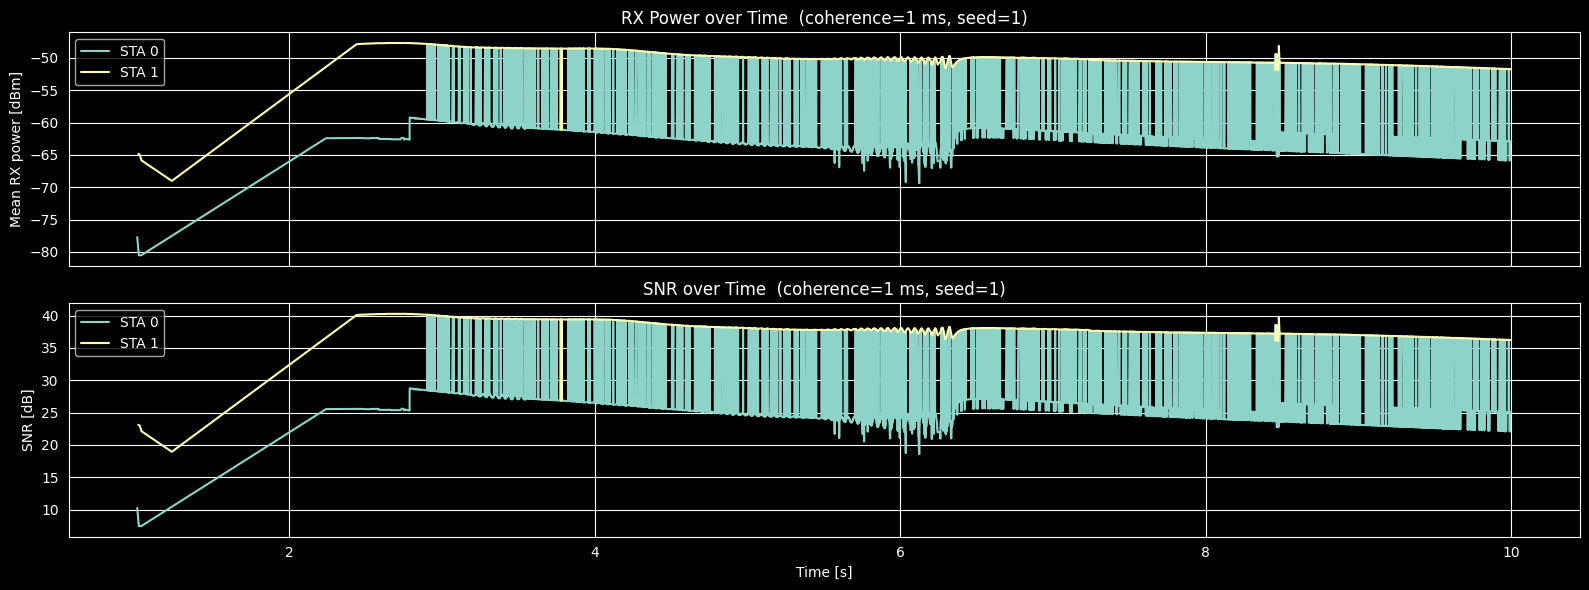

In [14]:
# ── 2. RX power and SNR over time (representative run, seed=1) ───────────
# Mirrors the pathloss-over-time line plot from plot3d_mobile_csi.py.
tc_ex = coherence_times[0]
df_ex = load_csv(snr_file(tc_ex, 1))

fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)

if df_ex is not None and not df_ex.empty:
    for sta_id, grp in df_ex.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        axes[0].plot(grp['Time_s'], grp['RxPower_dBm'], label=f'STA {int(sta_id)}')
        axes[1].plot(grp['Time_s'], grp['SNR_dB'],      label=f'STA {int(sta_id)}')
else:
    for ax in axes:
        ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
                transform=ax.transAxes, ha='center', va='center', color='red')

axes[0].set_ylabel('Mean RX power [dBm]')
axes[0].set_title(f'RX Power over Time  (coherence={tc_ex} ms, seed=1)')
axes[0].legend()

axes[1].set_ylabel('SNR [dB]')
axes[1].set_xlabel('Time [s]')
axes[1].set_title(f'SNR over Time  (coherence={tc_ex} ms, seed=1)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'snr_over_time_tc{tc_ex}.png', dpi=300, bbox_inches='tight', pad_inches=0.4)
plt.show()


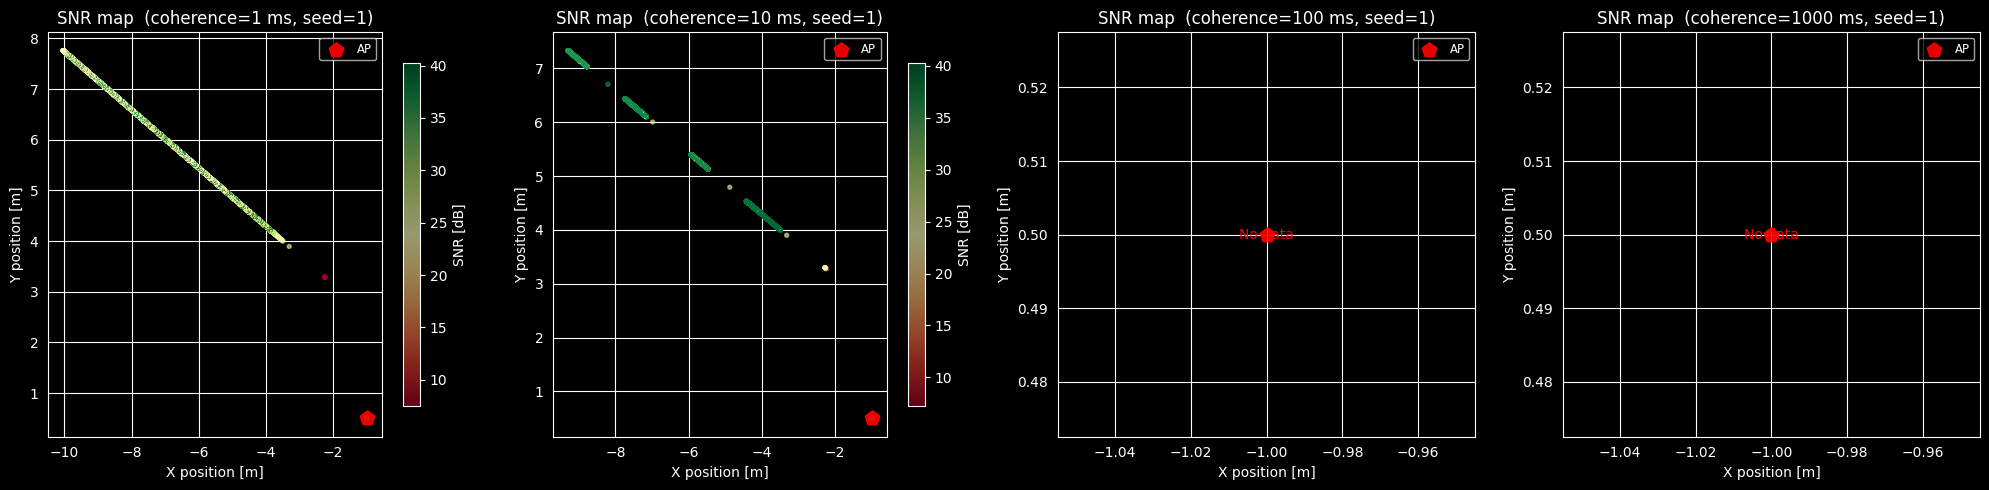

In [15]:
# ── 3. SNR heatmap on the floor-plan (seed=1 per coherence time) ─────────
# Colour = SNR value; AP shown as a red pentagon (same style as plot3d_mobile_csi.py).
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(snr_file(tc, 1))

    if df is not None and not df.empty:
        sc = ax.scatter(df['pos_x'], df['pos_y'],
                        c=df['SNR_dB'], cmap='RdYlGn',
                        s=8, alpha=0.6)
        plt.colorbar(sc, ax=ax, label='SNR [dB]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    # AP marker — red pentagon, same convention as plot3d_mobile_csi.py
    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'SNR map  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('snr_spatial.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


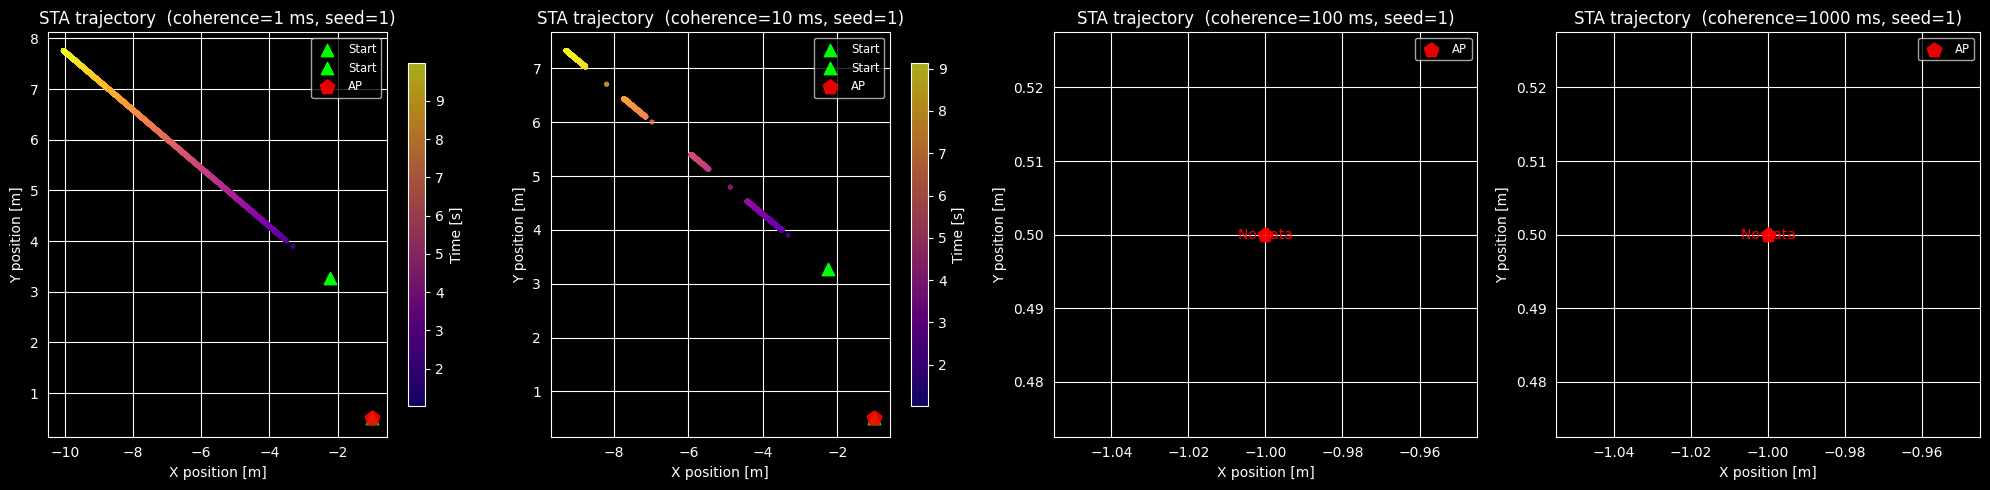

In [16]:
# ── 1. STA trajectory per coherence time (seed=1) ────────────────────────
# Colour-encodes simulation time; AP shown as a red pentagon.
ncols = len(coherence_times)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), squeeze=False)
axes = axes[0]

for idx, tc in enumerate(coherence_times):
    ax = axes[idx]
    df = load_csv(pos_file(tc, 1))

    if df is not None and not df.empty:
        for sta_id, grp in df.groupby('STA_NodeId'):
            grp = grp.sort_values('Time_s')
            sc  = ax.scatter(grp['pos_x'], grp['pos_y'],
                             c=grp['Time_s'], cmap='plasma',
                             s=8, alpha=0.7)
            # mark the start of the walk with a triangle
            ax.scatter(grp['pos_x'].iloc[0], grp['pos_y'].iloc[0],
                       marker='^', s=80, c='lime', zorder=5, label='Start')
        plt.colorbar(sc, ax=ax, label='Time [s]', shrink=0.85)
    else:
        ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                ha='center', va='center', color='red')

    ax.scatter(AP_X, AP_Y, marker='p', s=120, c='r', alpha=0.9,
               zorder=6, label='AP')
    ax.set_xlabel('X position [m]')
    ax.set_ylabel('Y position [m]')
    ax.set_title(f'STA trajectory  (coherence={tc} ms, seed=1)')
    ax.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.savefig('positions_trajectory.png', dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


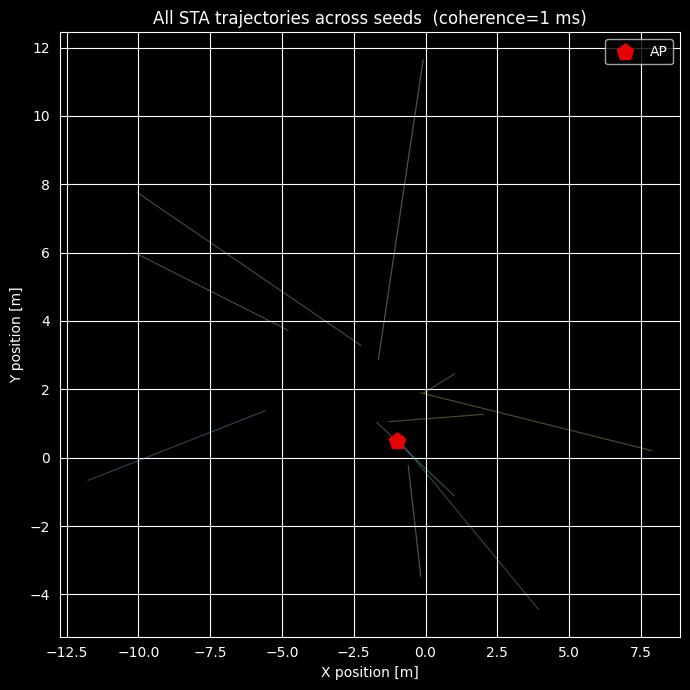

In [17]:
# ── 2. All seeds overlaid for one coherence time ─────────────────────────
# Good for checking how much trajectory variability exists across seeds.
tc_detail = coherence_times[0]
fig, ax   = plt.subplots(figsize=(7, 7))

for seed in range(1, num_seeds + 1):
    df = load_csv(pos_file(tc_detail, seed))
    if df is None or df.empty:
        continue
    for _, grp in df.groupby('STA_NodeId'):
        grp = grp.sort_values('Time_s')
        ax.plot(grp['pos_x'], grp['pos_y'], alpha=0.35, linewidth=0.9)

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'All STA trajectories across seeds  (coherence={tc_detail} ms)')
ax.legend()
plt.tight_layout()
plt.savefig(f'positions_all_seeds_tc{tc_detail}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()


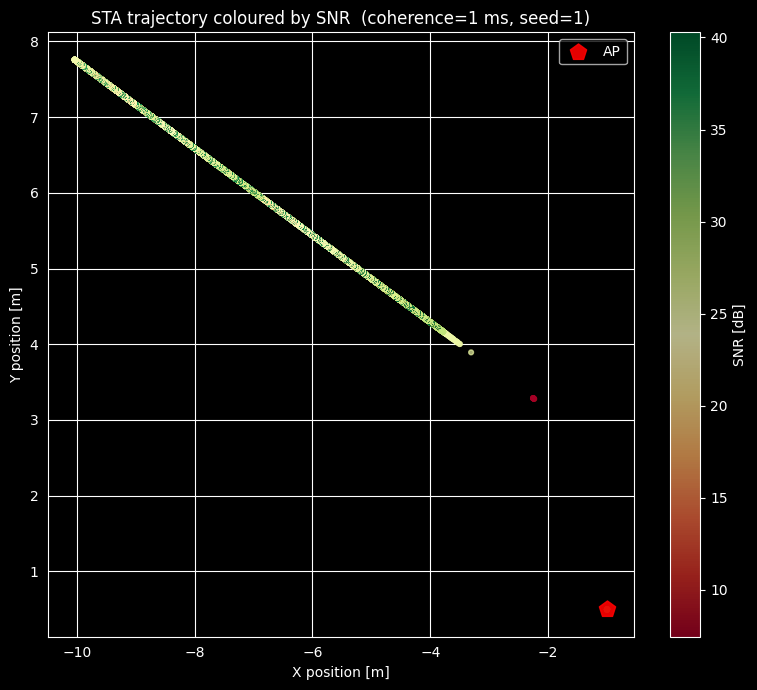

In [18]:
# ── 3. Trajectory coloured by SNR (combined snr + position data) ─────────
# Uses the SNR CSV which already contains position columns.
# This is the spatial view from plot3d_mobile_csi.py but with SNR as colour.
tc_ex = coherence_times[0]
df    = load_csv(snr_file(tc_ex, 1))   # SNR CSV already has pos_x / pos_y

fig, ax = plt.subplots(figsize=(8, 7))

if df is not None and not df.empty:
    sc = ax.scatter(df['pos_x'], df['pos_y'],
                    c=df['SNR_dB'], cmap='RdYlGn',
                    s=12, alpha=0.7)
    plt.colorbar(sc, ax=ax, label='SNR [dB]')
else:
    ax.text(0.5, 0.5, f'File not found:\n{snr_file(tc_ex, 1)}',
            transform=ax.transAxes, ha='center', va='center', color='red')

ax.scatter(AP_X, AP_Y, marker='p', s=150, c='r', alpha=0.9,
           zorder=6, label='AP')
ax.set_xlabel('X position [m]')
ax.set_ylabel('Y position [m]')
ax.set_title(f'STA trajectory coloured by SNR  (coherence={tc_ex} ms, seed=1)')
ax.legend()
plt.tight_layout()
plt.savefig(f'snr_trajectory_tc{tc_ex}.png',
            dpi=300, bbox_inches='tight', pad_inches=0.3)
plt.show()
